# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [24]:
# Load the transformed data from Assignment 7
df = pd.read_csv('cleaned_airbnb_data_7.csv')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30259 entries, 0 to 30258
Data columns (total 66 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            30259 non-null  int64  
 1   host_id                                       30259 non-null  int64  
 2   hosts_time_as_user_years                      29910 non-null  float64
 3   hosts_time_as_user_months                     29910 non-null  float64
 4   hosts_time_as_host_years                      29910 non-null  float64
 5   hosts_time_as_host_months                     29910 non-null  float64
 6   host_is_superhost                             29910 non-null  float64
 7   host_listings_count                           29910 non-null  float64
 8   host_has_profile_pic                          29910 non-null  float64
 9   host_identity_verified                        29910 non-null 

,id,host_id,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_is_superhost,host_listings_count,host_has_profile_pic,host_identity_verified,...,log_price,availability_365_minmax,log_price_zscore,review_volume,price_per_guest,long_term_stay,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,2539,2787,17.0,9.0,15.0,5.0,0.0,5.0,1.0,1.0,...,4.735935,0.928767,-0.631919,Medium,56.985,1,0,0,1,0
1,6848,15991,17.0,1.0,15.0,5.0,1.0,1.0,1.0,1.0,...,4.764479,0.523288,-0.591770,High,39.090,1,1,0,0,0
2,6872,16104,17.0,1.0,15.0,5.0,0.0,2.0,1.0,1.0,...,4.382776,0.783562,-1.128656,Low,80.060,1,0,0,1,0
3,6990,16800,17.0,1.0,15.0,5.0,1.0,1.0,1.0,1.0,...,4.346011,0.597260,-1.180368,High,77.170,1,0,0,1,0
4,7097,17571,17.0,0.0,15.0,5.0,1.0,2.0,1.0,1.0,...,5.310592,0.290411,0.176366,High,101.235,1,0,0,1,0


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. The dataset describes Airbnb listings. It includes host status and history, location (neighbourhood, latitude, longitude), size (accommodates, bathrooms, bedrooms, beds), price, minimum and maximum night rules, availability, review counts and scores, and room type. It also holds columns I built in Assignment 7, such as log_price, review_volume, price_per_guest, and long_term_stay.

2. The dataset has 30,259 rows and 66 columns. Each row is one listing.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [25]:
# Price spike from the median fill in Assignment 6
print(df['price'].value_counts().head(3))

# Remove listings with the filled-in price so the model learns from real prices
df = df[df['price'] != 174.69]

# The maximum night columns use a placeholder value
print(df['maximum_nights'].max())

drop_cols = [
    'id', 'host_id',  # ID numbers
    'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'property_type',
    'first_review', 'last_review', 'review_volume',  # text, date, and category columns
    'log_price', 'log_price_zscore', 'price_per_guest', 'price_quote_total_price',
    'price_quote_price_per_night', 'estimated_revenue_l365d',  # built from price
    'availability_365_minmax', 'minimum_minimum_nights', 'room_Entire home/apt',  # repeat other columns
    'maximum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights',
    'maximum_nights_avg_ntm'  # placeholder values
]
df = df.drop(columns=drop_cols)

# Linear regression cannot use rows with missing values
df = df.dropna()
print(df.shape)

price
174.69    8745
71.93       83
59.11       70
Name: count, dtype: int64
2147483647.0
(8163, 45)


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. The named columns (post_id, title, descr, details, address) are not in this dataset. I dropped ID numbers, text, date, and category columns, columns built from price, repeated columns, and the maximum night columns, which use a placeholder of 2,147,483,647. 8,745 listings share a price of $174.69, the median I used to fill missing prices in Assignment 6, so I removed them. After I dropped rows with missing values, 8,163 rows and 45 columns remained.

2. ID numbers are labels, but the model would treat them as amounts. Text columns would stop the model from running. Columns built from price would hand the model the answer, so the score would look strong but the model could not price a new listing. The placeholder and the filled prices would pull the coefficients toward values that are not real.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

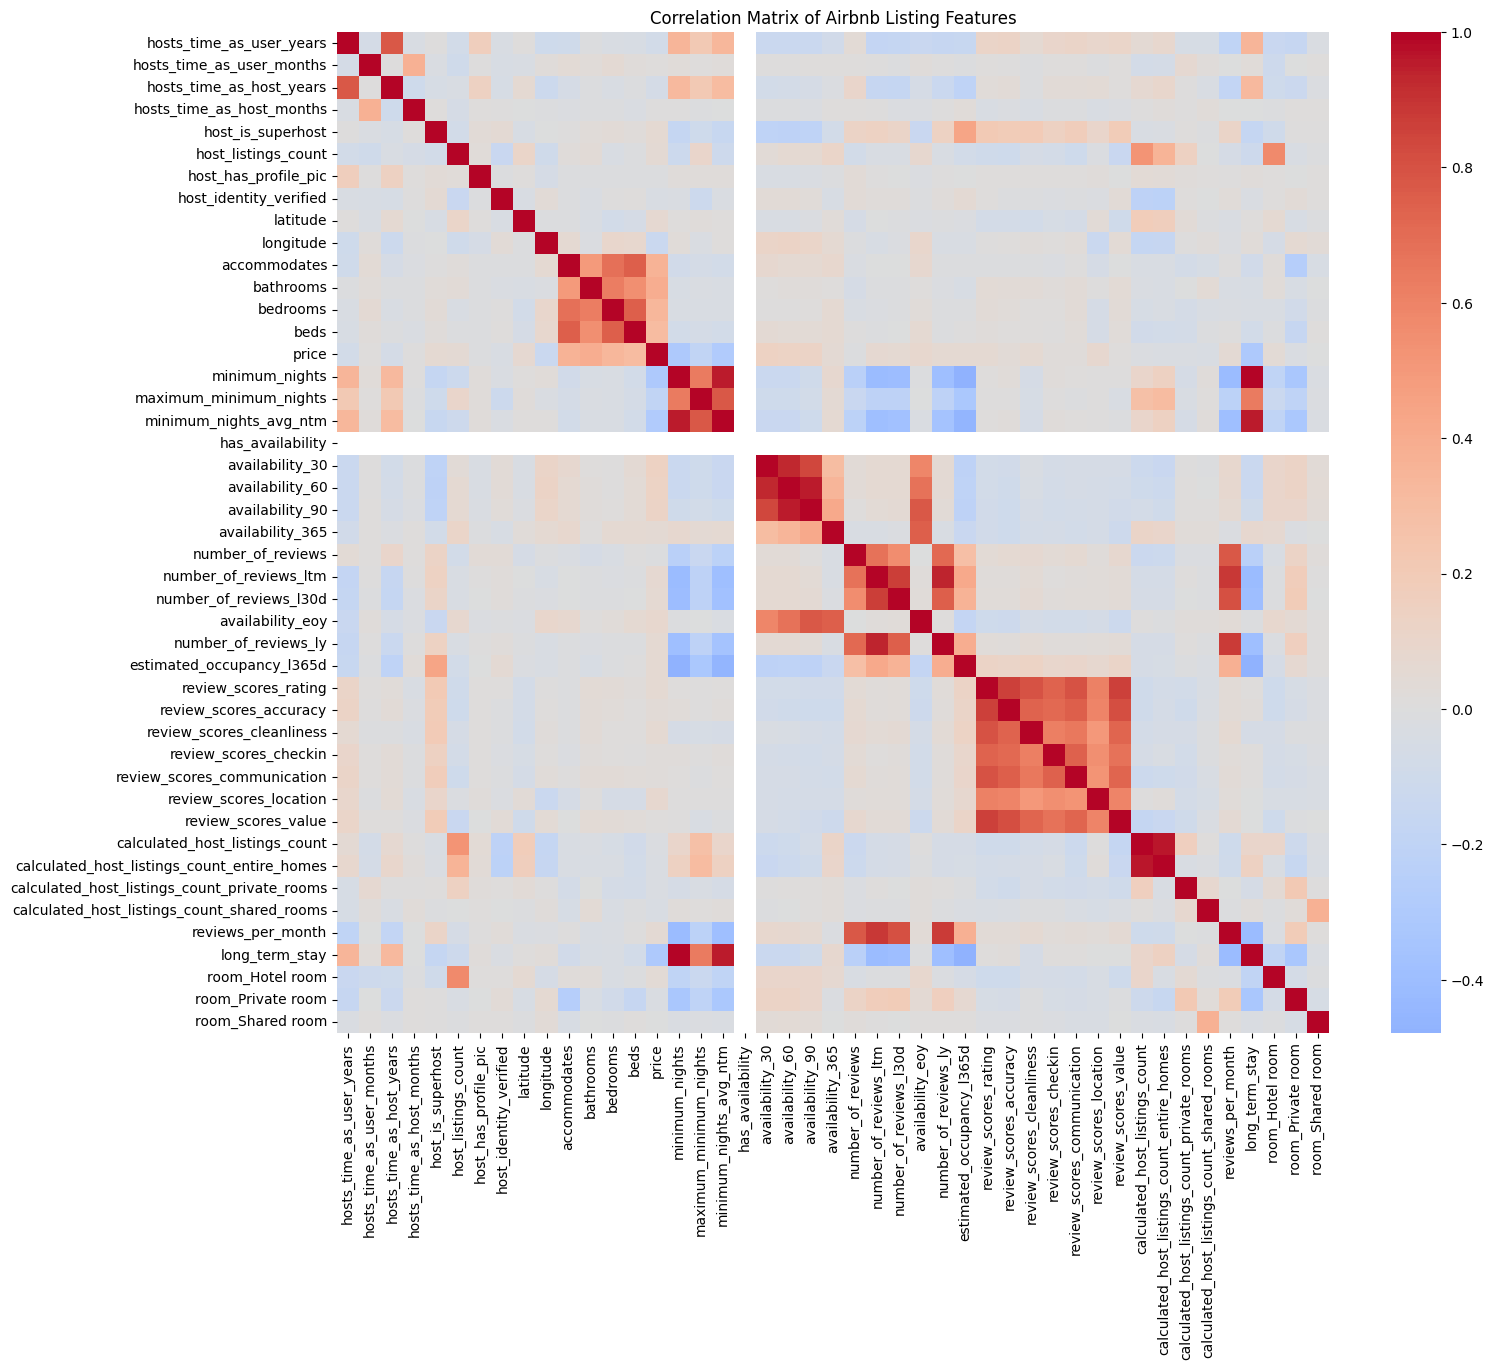

long_term_stay                                 -0.309856
minimum_nights                                 -0.307584
minimum_nights_avg_ntm                         -0.292188
maximum_minimum_nights                         -0.188135
longitude                                      -0.133364
hosts_time_as_user_years                       -0.083841
hosts_time_as_host_years                       -0.064703
host_identity_verified                         -0.038653
calculated_host_listings_count_shared_rooms    -0.030653
calculated_host_listings_count_private_rooms   -0.026053
room_Private room                              -0.025009
calculated_host_listings_count_entire_homes    -0.023463
calculated_host_listings_count                 -0.017169
host_has_profile_pic                           -0.015487
number_of_reviews                              -0.009150
room_Shared room                               -0.004403
hosts_time_as_host_months                       0.006058
hosts_time_as_user_months      

In [26]:
# Correlation matrix of the numeric columns
corr = df.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Airbnb Listing Features')
plt.show()

# Correlation of each variable with price
print(corr['price'].drop('price').sort_values())

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. Bathrooms had the strongest positive correlation with price at 0.39, followed by accommodates (0.36), bedrooms (0.34), and beds (0.31). The strongest negative correlations were long_term_stay (-0.31), minimum_nights (-0.31), and minimum_nights_avg_ntm (-0.29). No variable passed 0.4 in either direction, so each relationship is moderate at best.

2. The size columns and the minimum stay columns look like the most useful predictors. The heatmap shows that the columns within each group are also correlated with each other, so they overlap. availability_30 (0.14) and availability_60 (0.13) may add a little. has_availability shows NaN and a blank row in the heatmap because it has the same value for every listing, so it cannot predict price.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [27]:
# Price is the target
y = df['price']
print(y.describe().round(2))

# Every other column is a feature, except has_availability, which has no variation left
X = df.drop(columns=['price', 'has_availability'])
print(X.shape)
print(X.columns.tolist())

count     8163.00
mean       308.39
std        398.62
min         20.37
25%        140.46
50%        215.73
75%        347.26
max      10000.00
Name: price, dtype: float64
(8163, 43)
['hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_is_superhost', 'host_listings_count', 'host_has_profile_pic', 'host_identity_verified', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'minimum_nights', 'maximum_minimum_nights', 'minimum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'calculated_host_listings_count', 'calculated_host_listing

### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. I use 43 features, shown in the printed list. They cover host history and status, latitude and longitude, size, minimum stay rules, availability, review counts and scores, host listing counts, the long_term_stay flag, and three room type columns. I left out has_availability because it has no variation.

2. Price is a continuous dollar amount. In this data it runs from \$20.37 to \$10,000.00 with a median of \$215.73. Regression predicts a number on that scale. Classification predicts a category, such as the Low, Medium, and High groups in review_volume.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [28]:
# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(6530, 43) (1633, 43)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [29]:
# Fit the model on the training data
model = LinearRegression()
model.fit(X_train, y_train)

# Predict prices for the test set
y_pred = model.predict(X_test)

## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [30]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", round(mse, 2))
print("RMSE:", round(mse ** 0.5, 2))
print("R²:", round(r2, 4))

MSE: 114216.75
RMSE: 337.96
R²: 0.3187


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. The R² is 0.3187. The model explains about 32% of the variation in price across the 1,633 test listings. The rest of the variation is left unexplained, so its predictions are rough estimates.

2. The MSE of 114,216.75 is in squared dollars, so the RMSE of \$337.96 is easier to read. A typical miss of \$337.96 is larger than the median price of \$215.73, so the error is large. The mean price (\$308.39) sits well above the median, and the maximum is \$10,000.00. I could predict log price, remove extreme prices, and encode neighbourhood_group_cleansed and property_type, which I dropped as text.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [31]:
# Table of coefficients, sorted by absolute size
coef_table = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_})
coef_table['abs_coefficient'] = coef_table['coefficient'].abs()
coef_table = coef_table.sort_values('abs_coefficient', ascending=False)
coef_table

,feature,coefficient,abs_coefficient
9,longitude,-805.009196,805.009196
8,latitude,564.110813,564.110813
39,long_term_stay,-345.091640,345.091640
11,bathrooms,184.192934,184.192934
40,room_Hotel room,-153.218838,153.218838
7,host_identity_verified,-112.913291,112.913291
33,review_scores_value,-111.640121,111.640121
27,review_scores_rating,101.084471,101.084471
41,room_Private room,-78.112531,78.112531
32,review_scores_location,69.766566,69.766566


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. Latitude had the largest positive coefficient, at \$564.11 per degree north. Bathrooms came next at \$184.19 per bathroom, then review_scores_rating at \$101.08 per point and review_scores_location at \$69.77 per point. Each coefficient holds the other features constant.

2. Yes. room_Hotel room is -153.22 compared with entire homes, though its correlation with price was a positive 0.05. host_identity_verified is -112.91, and review_scores_value is -111.64 while review_scores_rating is 101.08. The review score columns are closely correlated in the heatmap, so their coefficients can offset each other.

3. Location and bathrooms are tied to larger price differences than most other features in this model. long_term_stay is -345.09, so listings with that flag price lower when other features are equal. Airbnb could show hosts how these features compare across similar listings. The signs on review scores and room type need more checks before anyone acts on them.

## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [32]:
# Keep the five features with the largest absolute coefficients
top_features = coef_table['feature'].head(5).tolist()
print(top_features)

# Rebuild the model with only those features
refined_model = LinearRegression()
refined_model.fit(X_train[top_features], y_train)
y_pred_refined = refined_model.predict(X_test[top_features])

mse_refined = mean_squared_error(y_test, y_pred_refined)
r2_refined = r2_score(y_test, y_pred_refined)

# Compare the two models
print("Baseline MSE:", round(mse, 2), "  R²:", round(r2, 4))
print("Refined MSE: ", round(mse_refined, 2), "  R²:", round(r2_refined, 4))

['longitude', 'latitude', 'long_term_stay', 'bathrooms', 'room_Hotel room']
Baseline MSE: 114216.75   R²: 0.3187
Refined MSE:  126910.96   R²: 0.2429


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. I kept longitude, latitude, long_term_stay, bathrooms, and room_Hotel room. These five had the largest absolute coefficients in the Section 8 table, which is the rule the task gives.

2. No. R² fell from 0.3187 to 0.2429, and MSE rose from 114,216.75 to 126,910.96. A coefficient measures the change in price for one unit of a feature, so a degree of longitude and a 0/1 flag are not on the same scale. The rule dropped accommodates (0.36) and bedrooms (0.34), which had stronger correlations with price than three of the five features I kept.

3. I would recommend the baseline model. It has the higher R² and the lower MSE on the same test set. It still explains only about 32% of the variation, so stakeholders should treat its predictions as a starting point.

4. My second learning outcome is: "I will be able to evaluate AI-generated categorizations against the source financials by treating each output as a hypothesis to verify rather than an answer to trust, so I can frame which discrepancies actually matter before they reach a quality-of-earnings conclusion." The top-five rule came from the assignment, and I checked it the way I would check an AI output. I treated it as a hypothesis and tested it on the same data. The R² fell and the MSE rose, so the rule did not hold.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The model asked which listing features are linked to price and how well those features predict the price of a listing. Size, location, minimum stay rules, and review scores carry the most weight, but together all 43 features explain about 32% of the variation in price.

2. Hosts should compare their price against listings with similar bathrooms, location, and stay rules, since those features carried large coefficients. Airbnb should not set prices from this model alone, because a typical miss of \$337.96 is larger than the median price of \$215.73. It could use the model as one input in a pricing tool.

3. I would predict log price, encode neighbourhood_group_cleansed and property_type, and remove columns that overlap, such as the review score group. After I removed the filled prices and the rows with missing values, 8,163 of 30,259 rows remained. If I filled the missing bedroom and review values, the model would have more listings to learn from.

4. My first learning outcome is: "I will be able to build a Python workflow that cleans and consistently categorizes messy client transaction data, so a diligence team can flag non-recurring items and quality-of-earnings adjustments without re-sorting by hand." Most of the work here was cleaning before the model ran. The 8,745 filled prices and the 2,147,483,647 placeholder acted like one-time items in a client ledger. If I had left them in, they would have pulled the model toward values that were not real.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [33]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"

[NbConvertApp] Converting notebook assignment_11_regression.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 697978 bytes to assignment_11_regression.html
